<a href="https://colab.research.google.com/github/klorenzoe/hotel-booking-ML-project/blob/feat%2F3%2Ffeature-engineering/hotel_booking_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1 - [Jorge] Recolección y calidad del dato

**Hotel Booking Demand · Universidad de Deusto**

**Objetivos cuando se está realizando la reserva:**

1. Predecir **si se cancelará** (`is_canceled`)
2. Predecir **tarifa media diaria** (`adr`, *average daily rate*: según el paper, la suma de lo facturado por alojamiento
÷ el número de noches de estancia; tabla 1, p. 43)

**Origen de los datos**

- **Paper:** Antonio, de Almeida y Nunes (2019), [*Hotel booking demand datasets*](https://doi.org/10.1016/j.dib.2018.11.126),
  *Data in Brief* 22, 41–49 · CC BY 4.0.
- **Copia usada:** [TidyTuesday 2020-02-11](https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv) (los dos hoteles en un solo CSV).

## 1.1 Preparar el entorno

In [100]:
import hashlib
import json
import platform
from datetime import datetime, timezone
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)

ROOT = Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "hotels.csv"
OUT_DIR = ROOT / "outputs" / "01-data-collection-and-quality"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def check(condition, ok, fail):
    """Print ✅ if the condition holds and ⚠️ otherwise."""
    print(f"✅ {ok}" if bool(condition) else f"⚠️ {fail}")


def pct(mask):
    """True values in %."""
    return round(mask.mean() * 100, 1)


def sha256_file(path: Path) -> str:
    """File fingerprint: if a single byte changes, the hash changes."""
    return hashlib.sha256(path.read_bytes()).hexdigest()



## 1.2 ¿El fichero es el correcto?

In [101]:
SOURCE: dict[str, str] = {
    "name": "hotel-booking-demand",
    "doi": "10.1016/j.dib.2018.11.126",
    "license": "CC BY 4.0",
    "url": "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv",
    "expected_sha256": "7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06",
}

# Expected Values
EXPECTED_ROWS = 119_390  # Paper: Abstract (40,060 + 79,330)
EXPECTED_COLS = 32       # Paper: Abstract (31 variables) + hotel (TidyTuesday)

H1_NAME = "Resort Hotel" # Name by Tidytuesday
H1_BOOKINGS = 40_060     # Paper: Abstract
H1_CANCELED = 11_122     # Paper: Table 3

H2_NAME = "City Hotel"   # Name by Tidytuesday
H2_BOOKINGS = 79_330     # Paper: Abstract
H2_CANCELED = 33_102     # Paper: Table 6

PAPER = pd.DataFrame([
    [H1_NAME, H1_BOOKINGS, H1_CANCELED],
    [H2_NAME, H2_BOOKINGS, H2_CANCELED],
], columns=["hotel", "bookings", "canceled"]).set_index("hotel")


# Download raw data only if missing
if not RAW_PATH.exists():
    RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(SOURCE["url"], RAW_PATH)


# Read all csv as text
raw = pd.read_csv(RAW_PATH, dtype=str, keep_default_na=False)
raw_sha256: str = sha256_file(RAW_PATH)

# Only the canceled bookings
raw_canceled = raw[raw["is_canceled"] == "1"]


per_hotel = pd.DataFrame({
    "bookings": raw["hotel"].value_counts(),
    "canceled": raw_canceled["hotel"].value_counts(),
}).reindex(PAPER.index) # same index order as PAPER


paper_counts_ok: bool = per_hotel.equals(PAPER)
hash_match_ok = raw_sha256 == SOURCE["expected_sha256"]
rows_cols_match_ok = raw.shape == (EXPECTED_ROWS, EXPECTED_COLS)

check(paper_counts_ok, "Bookings and cancellations counts match the paper.", "Counts differ from the paper.")
check(hash_match_ok, "Hash matches.", "Hash differs: the file changed.")
check(rows_cols_match_ok, f"{EXPECTED_ROWS} rows x {EXPECTED_COLS} columns.", f"Unexpected shape: {raw.shape}.")
per_hotel.join(PAPER.add_suffix(" (paper)"))

✅ Bookings and cancellations counts match the paper.
✅ Hash matches.
✅ 119390 rows x 32 columns.


,bookings,canceled,bookings (paper),canceled (paper)
hotel,,,,
Resort Hotel,40060,11122,40060,11122
City Hotel,79330,33102,79330,33102


## 1.3 ¿Qué representa una fila y cada columna?

- Cada fila es **una reserva**.
- El `role` dice para qué sirve cada columna:
    - `feature`: posible entrada del modelo.
    - `target_cls` / `target_reg`: lo que predecimos.
    - `forbidden`: está en el fichero, pero se rellena después de reservar: **nunca** puede ser entrada.
    - `outcome`: el desenlace de la reserva: **nunca** puede ser entrada.



In [102]:
DATA_DICTIONARY = pd.DataFrame([
    ("hotel",                          "categorical", "feature"),
    ("is_canceled",                    "binary",      "target_cls"),
    ("lead_time",                      "count_days",  "feature"),
    ("arrival_date_year",              "date_part",   "feature"),
    ("arrival_date_month",             "date_part",   "feature"),
    ("arrival_date_week_number",       "date_part",   "feature"),
    ("arrival_date_day_of_month",      "date_part",   "feature"),
    ("stays_in_weekend_nights",        "count",       "feature"),
    ("stays_in_week_nights",           "count",       "feature"),
    ("adults",                         "count",       "feature"),
    ("children",                       "count",       "feature"),
    ("babies",                         "count",       "feature"),
    ("meal",                           "categorical", "feature"),
    ("country",                        "categorical", "forbidden"),
    ("market_segment",                 "categorical", "feature"),
    ("distribution_channel",           "categorical", "feature"),
    ("is_repeated_guest",              "binary",      "feature"),
    ("previous_cancellations",         "count",       "feature"),
    ("previous_bookings_not_canceled", "count",       "feature"),
    ("reserved_room_type",             "categorical", "feature"),
    ("assigned_room_type",             "categorical", "forbidden"),
    ("booking_changes",                "count",       "forbidden"),
    ("deposit_type",                   "categorical", "forbidden"),
    ("agent",                          "id_code",     "feature"),
    ("company",                        "id_code",     "feature"),
    ("days_in_waiting_list",           "count_days",  "feature"),
    ("customer_type",                  "categorical", "feature"),
    ("adr",                            "continuous",  "target_reg"),
    ("required_car_parking_spaces",    "count",       "forbidden"),
    ("total_of_special_requests",      "count",       "feature"),
    ("reservation_status",             "categorical", "outcome"),
    ("reservation_status_date",        "date",        "outcome"),
], columns=["column", "analytic_type", "role"])

check(set(DATA_DICTIONARY["column"]) == set(raw.columns), "The dictionary covers all 32 columns.", "Dictionary and file do not match.")
DATA_DICTIONARY["role"].value_counts()

✅ The dictionary covers all 32 columns.


,count
role,
feature,23
forbidden,5
outcome,2
target_cls,1
target_reg,1


**Se crea una copia tipada de los datos.**

- Los datos `raw` no se tocan.

- Se crea `df` como copia **tipada** de `raw` usando los tipos establecidos por `DATA_DICTIONARY`.

- La conversión no puede perder datos: solo los `"NA"` de `children` pueden quedar vacíos.

In [103]:
# Numeric columns, by their type in the data dictionary
NUMERIC_TYPES = ["binary", "count", "count_days", "continuous"]
NUMERIC_COLS: list[str] = DATA_DICTIONARY.query("analytic_type in @NUMERIC_TYPES")["column"].tolist()

df = raw.copy()

# Text to numbers: anything that is not a number becomes empty
df[NUMERIC_COLS] = df[NUMERIC_COLS].apply(pd.to_numeric, errors="coerce")

# Year + month + day → one arrival date
arrival_text = raw["arrival_date_year"] + "-" + raw["arrival_date_month"] + "-" + raw["arrival_date_day_of_month"]
df["arrival_date"] = pd.to_datetime(arrival_text, format="%Y-%B-%d", errors="coerce")

df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

# Only the "NA" sentinel of children may become empty
children_na = int((raw["children"] == "NA").sum())
empty_per_column = df[NUMERIC_COLS].isna().sum()
empty_columns = empty_per_column[empty_per_column > 0].to_dict()

no_data_lost_ok = empty_columns == {"children": children_na}
arrival_dates_ok = df["arrival_date"].notna().all()

check(no_data_lost_ok, f"Only the {children_na} 'NA' of children became empty.", f"Unexpected empty values: {empty_columns}.")
check(arrival_dates_ok, "Every arrival date is valid.", "Some arrival dates could not be built.")

✅ Only the 4 'NA' of children became empty.
✅ Every arrival date is valid.


## 1.4 ¿Hay duplicados?

**Consideraciones**

- **No existe ID de reserva:** los autores eliminan toda identificación de hotel y cliente por temas de privacidad (*Abstract*, p. 41).

- **Duplicado ambiguo:** una fila repetida puede ser un error o dos reservas parecidas (p. ej., de un grupo).

- **Alcance:** esta sección solo mide; el tratamiento se decide en el 02.

In [104]:
# Every row that has at least one exact copy (the first one included)
dup_all = raw.duplicated(keep=False)

# Only the extra copies (the first one counts as the original)
dup_extra = raw.duplicated()

pd.Series({
    "extra copies (%)": pct(dup_extra),
    "cancel rate, rows with copies (%)": pct(df.loc[dup_all, "is_canceled"] == 1),
    "cancel rate, unique rows (%)": pct(df.loc[~dup_all, "is_canceled"] == 1),
}, name="value").to_frame()


,value
extra copies (%),26.8
"cancel rate, rows with copies (%)",58.4
"cancel rate, unique rows (%)",26.2


**Conclusiones**

- **Muchas copias:** el `26.8 %` de las filas sobra (`dup_extra`); son copias exactas de otra fila.
- **Las copias se cancelan más:** `is_canceled = 1` en el `58.4 %` de las filas con copias (`dup_all`), frente al
  `26.2 %` de las filas únicas (`unique_rows`): más del doble.
- **Riesgo de fuga:** dos copias tienen el mismo `is_canceled`. Si una cae en *train* y la otra en *test*, el
  modelo se evalúa con una fila que ya vio, y las métricas salen mejores de lo real.
- **Implicación:** las filas de un mismo grupo de `dup_all` deben ir al mismo lado de la partición (se decide en
  el 02).

## 1.5 ¿Qué columnas no se pueden usar?

**Consideraciones**

- **Reglas:**
    - El modelo predice al registrar la reserva.
    - Una columna que se rellena después es **fuga**.

- **Momento del dato:**
    - Cada registro es de la **víspera de la llegada**, no del momento de reservar (*Specifications table*, p. 42).
    - Si un valor cambió entre la reserva y la llegada, solo queda el último; es decir, el valor original al reservar no se puede recuperar.

- **Último estado:** Las siguientes variables reflejan el estado final de la reserva (tabla 1, pp. 43-45):
    - `is_canceled`
    - `reservation_status`
    - `reservation_status_date`
    - `days_in_waiting_list`

- **Prohibidas:** Se conocen después de reservar o son el propio desenlace.

- **Dudosas:** Existen al reservar, pero pueden cambiar antes de la llegada (*§2*, pp. 45-46). Se puede probar con y sin ellas, con una lista distinta por tarea.


In [105]:
# Filled in after booking, or the outcome itself → never an input
FORBIDDEN: list[str] = [
    "required_car_parking_spaces",  # data: always 0 in canceled bookings → filled in on arrival
    "booking_changes",              # paper (Table 1, p. 43): counts changes until check-in or cancellation
    "assigned_room_type",           # paper (Table 1, p. 43): can differ from the reserved type; data: set at check-in
    "deposit_type",                 # paper (Table 1, p. 43): depends on payments made until arrival or cancellation
    "country",                      # paper (§2, p. 45): often corrected at check-in; data: PRT far more common among canceled
    "reservation_status",           # paper (Table 1, p. 44): final status = the target
    "reservation_status_date",      # paper (Table 1, p. 45): date the final status was set
]

# Known at booking, but stored as of the day before arrival (paper: Specifications table, p. 42).
UNDER_REVIEW: dict[str, list[str]] = {
    "classification": [
        "stays_in_*_nights",           # paper (§2, p. 46): differ between canceled and kept bookings
        "adults / children / babies",  # paper (§2, p. 46): differ between canceled and kept bookings
        "meal",                        # paper (§2, p. 46): differs between canceled and kept bookings
        "days_in_waiting_list",        # paper (Table 1, p. 43): known only once the booking is confirmed
        "total_of_special_requests",   # requests can be added until arrival
        "adr (as an input)",           # paper (Table 1, p. 43): depends on the final stay
    ],
    "regression": [  # nights, guests and meal set the price → allowed
        "days_in_waiting_list",
        "total_of_special_requests",
    ],
}

# FORBIDDEN must match the roles of the data dictionary
DATA_FORBIDDEN = DATA_DICTIONARY.query("role in ['forbidden', 'outcome']")
COLS_FORBIDDEN = DATA_FORBIDDEN["column"]
forbidden_ok = set(FORBIDDEN) == set(COLS_FORBIDDEN)
check(
    condition=forbidden_ok,
    ok="FORBIDDEN matches the data dictionary roles.",
    fail="FORBIDDEN does not match the data dictionary.",
)

✅ FORBIDDEN matches the data dictionary roles.


In [106]:
canceled = df["is_canceled"] == 1


def by_outcome(mask: pd.Series, name: str) -> pd.DataFrame:
    """Share of True values (%) among arrived and canceled bookings."""
    return pd.DataFrame({"arrived": [pct(mask[~canceled])], "canceled": [pct(mask[canceled])]}, index=[name])

✅ is_canceled = 1 <---> Canceled or No-Show (1,207 no-shows).


In [107]:
# Evidence: parking is filled in on arrival
by_outcome(df["required_car_parking_spaces"] > 0, "with parking (%)")

,arrived,canceled
with parking (%),9.9,0.0


- **Ninguna** reserva cancelada lo tiene (`0.0 %` frente a `9.9 %` de las que llegan).
- El paper no dice cuándo se registra.
- Los datos apuntan a que se anota al llegar; es decir, se prohíbe por los datos, no por el paper.

**Habitación asignada** (`assigned_room_type`)

In [46]:
# Evidence: the room is assigned at check-in
by_outcome(raw["assigned_room_type"] != raw["reserved_room_type"], "assigned room ≠ reserved (%)")

,arrived,canceled
assigned room ≠ reserved (%),18.8,1.8


- El paper dice que puede diferir de la reservada (`reserved_room_type`) por *overbooking* o a petición del cliente.
- Cambia en el `18.8 %` de las reservas que llegan y solo en el `1.8 %` de las canceladas.
- Todo apunta a que se asigna en el *check-in*.

**Cambios en la reserva** (`booking_changes`)

In [47]:
# Evidence: changes are counted until check-in or cancellation
by_outcome(df["booking_changes"] > 0, "with booking changes (%)")

,arrived,canceled
with booking changes (%),20.3,6.4


- El paper los cuenta hasta el *check-in* o la cancelación.
- El `20.3 %` de las que llegan tiene alguno, frente al `6.4 %` de las canceladas.
- Una reserva que acaba de entrar siempre tendría 0.

**Depósito** (`deposit_type`)

In [48]:
# Evidence: the deposit depends on payments made until arrival or cancellation
by_outcome(raw["deposit_type"] == "Non Refund", "Non Refund (%)")

,arrived,canceled
Non Refund (%),0.1,32.8


- El paper lo calcula con los pagos hechos **antes de la llegada o de la cancelación**, no al reservar.
- Por eso `Non Refund` casi solo aparece en canceladas (`32.8 %` frente a `0.1 %`).

**País** (`country`)

In [49]:
# Evidence: the country is often corrected at check-in
by_outcome(raw["country"] == "PRT", "from Portugal (%)")

,arrived,canceled
from Portugal (%),28.0,62.2


- El paper avisa de que la nacionalidad a menudo no se sabe hasta el *check-in*.
- `PRT` aparece en el `62.2 %` de las canceladas y solo en el `28.0 %` de las que llegan.
- Todo apunta a que, mientras no se corrige, el país por defecto es Portugal, y solo las que llegan pasan por el *check-in*.
- Se prohíbe en las dos tareas.

**Desenlace** (`reservation_status`)

In [50]:
# Evidence: reservation_status is the target (Canceled or No-Show → is_canceled = 1)
status_canceled = raw["reservation_status"].isin(["Canceled", "No-Show"])
flag_canceled = raw["is_canceled"] == "1"
target_ok = (status_canceled == flag_canceled).all()
n_no_show = (raw["reservation_status"] == "No-Show").sum()
check(
    condition=target_ok,
    ok=f"is_canceled = 1 ⇔ Canceled or No-Show ({n_no_show:,} no-shows).",
    fail="is_canceled does not match reservation_status.",
)

✅ is_canceled = 1 ⇔ Canceled or No-Show (1,207 no-shows).


- Es el desenlace; es decir, `Canceled` y `No-Show` son `is_canceled = 1`.
- El objetivo es «cancela **o no se presenta**».



---



**Dudosas** (`UNDER_REVIEW`)

- No se prohíben porque el dato existe al reservar.
- Lo que no se sabe es cuánto cambió hasta la víspera de la llegada.
- El comentario de cada una en el código dice por qué es dudosa.

- **La lista depende de la tarea:**
    - **Clasificación:** Noches (`stays_in_weekend_nights`, `stays_in_week_nights`), huéspedes (`adults`, `children`, `babies`) y régimen (`meal`) son dudosas porque se distribuyen distinto entre canceladas y no canceladas; es decir, pueden delatar el desenlace.
    - **Regresión:** Son justo lo que se cotiza (el precio por noche, `adr`, se calcula para esas noches, esas personas y ese régimen). Se admiten como entrada, con la limitación de que el valor guardado es el de la víspera.
    - El 03 medirá cada modelo con y sin sus dudosas.

## 1.6 ¿Cuánta calidad tienen los datos?

**Consideraciones**

- **Dimensiones:** Una pregunta por dimensión:
    - **Completitud** (`completeness`): ¿**Falta** el dato?
    - **Validez** (`validity`): ¿El valor es **posible**?

In [51]:
ADR_MAX: int = 1_000  # domain limit (the 2nd highest adr is 510)
guests = df["adults"] + df["children"].fillna(0) + df["babies"]

quality = pd.DataFrame([
    ("completeness", "adr present (%)",                pct(df["adr"].notna())),
    ("completeness", "country present (%)",            pct(raw["country"] != "NULL")),
    ("validity",     "is_canceled in {0, 1} (%)",      pct(df["is_canceled"].isin([0, 1]))),
    ("validity",     "arrival 2015-07 to 2017-08 (%)", pct(df["arrival_date"].between("2015-07-01", "2017-08-31"))),
    ("validity",     "rows with adr < 0",              int((df["adr"] < 0).sum())),
    ("validity",     f"rows with adr > {ADR_MAX}",     int((df["adr"] > ADR_MAX).sum())),
    ("validity",     "rows without guests",            int((guests == 0).sum())),
    ("validity",     "rows with 0 nights",             int((df["total_nights"] == 0).sum())),
], columns=["dimension", "metric", "value"])
quality

,dimension,metric,value
0,completeness,adr present (%),100.0
1,completeness,country present (%),99.6
2,validity,"is_canceled in {0, 1} (%)",100.0
3,validity,arrival 2015-07 to 2017-08 (%),100.0
4,validity,rows with adr < 0,1.0
5,validity,rows with adr > 1000,1.0
6,validity,rows without guests,180.0
7,validity,rows with 0 nights,715.0


**Lectura**

- **Objetivos:** Están completos y son válidos.

- **Filas imposibles:**
    - Hay 182 (`adr` negativo, `adr` de 5 400, sin huéspedes).
    - Pasan a cuarentena en el 02.

- **Reservas de 0 noches:**
    - Hay 715.
    - `adr` es "por noche"; es decir, sin noches no tiene sentido.
    - Quedan fuera de la regresión.

## 1.7 ¿A quién representan?

In [52]:
pd.Series({
    "City Hotel (%)": pct(raw["hotel"] == "City Hotel"),
    "guests from Portugal (%)": pct(raw["country"] == "PRT"),
    "months covered": df["arrival_date"].dt.to_period("M").nunique(),
}, name="value").to_frame()

,value
City Hotel (%),66.4
guests from Portugal (%),40.7
months covered,26.0


**Lectura**

- **Alcance:** Son dos hoteles portugueses entre 2015 y 2017; es decir, el modelo **no es general**.

- **Estacionalidad:**
    - Son 26 meses: julio y agosto aparecen tres veces.
    - Por eso las medias por mes tiran tienden a temporada de verano.

## 1.8 ¿Pasa el lote al notebook 02?

**Consideraciones**

- **Controles:** Cada control es **PASS** o **FAIL**.

- **Regla:** La decisión depende de qué falla:

| Situación | Decisión |
|---|---|
| Falla un control **crítico** que afecta a todo el `dataset` | `QUARANTINE`: se para |
| Falla otra cosa (filas o columnas concretas) | `CONTINUE_WITH_CONDITIONS` |
| Todo pasa | `PUBLISH` |

In [68]:
q = quality.set_index("metric")["value"]
impossible = (df["adr"] < 0) | (df["adr"] > ADR_MAX) | (guests == 0)

targets_valid_ok = q["is_canceled in {0, 1} (%)"] == 100 and q["adr present (%)"] == 100
period_covered_ok = q["arrival 2015-07 to 2017-08 (%)"] == 100
exact_copies_less_than_5_pct_ok = pct(dup_extra) < 5
zero_nights_ok = q["rows with 0 nights"] == 0

scorecard = pd.DataFrame([
    # control,           scope,      passed,                                              severity,   on failure
    ("paper_counts",      "dataset",  paper_counts_ok,                 "critical", "investigate"),
    ("source_hash",       "dataset",  hash_match_ok,                   "critical", "download again"),
    ("rows_and_columns",  "dataset",  rows_cols_match_ok,              "critical", "investigate"),
    ("targets_valid",     "dataset",  targets_valid_ok,                "critical", "investigate"),
    ("period_covered",    "dataset",  period_covered_ok,               "critical", "investigate"),
    ("exact_copies_<5%",  "dataset",  exact_copies_less_than_5_pct_ok, "warning",  "define a duplicates policy"),  # 5 %: see note below
    ("impossible_rows",   "row",      not impossible.any(),            "critical", "quarantine"),
    ("zero_nights",       "row",      zero_nights_ok,                  "warning",  "exclude from the regression"),
    ("forbidden_columns", "features", len(FORBIDDEN) == 0,             "critical", "exclude from the features"),
], columns=["control", "scope", "passed", "severity", "on_failure"])
scorecard["passed"] = scorecard["passed"].astype(bool)

blocking = scorecard.query("not passed and severity == 'critical' and scope == 'dataset'")
batch_decision: str = "QUARANTINE" if len(blocking) else ("PUBLISH" if scorecard["passed"].all() else "CONTINUE_WITH_CONDITIONS")

print("Batch decision:", batch_decision)

scorecard

Batch decision: CONTINUE_WITH_CONDITIONS


,control,scope,passed,severity,on_failure
0,paper_counts,dataset,True,critical,investigate
1,source_hash,dataset,True,critical,download again
2,rows_and_columns,dataset,True,critical,investigate
3,targets_valid,dataset,True,critical,investigate
4,period_covered,dataset,True,critical,investigate
5,exact_copies_<5%,dataset,False,warning,define a duplicates policy
6,impossible_rows,row,False,critical,quarantine
7,zero_nights,row,False,warning,exclude from the regression
8,forbidden_columns,features,False,critical,exclude from the features


**Lectura**

- **`forbidden_columns`:**
    - Falla **a propósito**, porque las columnas están en el fichero.
    - Se cumple cuando el 03 las deje fuera del modelo.

- **`exact_copies_<5%`:**
    - El 5 % es una convención; es decir, no sale de los datos.
    - Por eso el control es solo un **aviso** (no para el lote).
    - Su efecto es obligar a decidir qué hacer con los duplicados.
    - Con un 26.8 % de copias, el aviso salta con cualquier umbral razonable.

## 1.9 Guardar lo que necesita el notebook 02

- **Contrato** (`data_contract.json`): Qué columnas hay, qué significan y cuáles están prohibidas.

- **Resumen** (`quality_summary.json`): La decisión, las tareas pendientes y con qué se ejecutó.

In [54]:
SENTINELS: dict[str, dict[str, str]] = (
    {  # text codes with a special meaning; "source" = who defines it
        "agent": {
            "value": "NULL",
            "meaning": "not applicable (booking without an agency)",
            "source": "paper (§2, p. 45)",
        },
        "company": {
            "value": "NULL",
            "meaning": "not applicable (booking without a company)",
            "source": "paper (§2, p. 45)",
        },
        "meal": {
            "value": "Undefined",
            "meaning": "same as SC (no meal plan)",
            "source": "paper (Table 1, p. 44)",
        },
        # paper (§2, p. 45): the PMS has no missing data -> reading these as "missing" is a project decision
        "children": {
            "value": "NA",
            "meaning": "missing",
            "source": "our decision"
        },
        "country": {
            "value": "NULL",
            "meaning": "missing",
            "source": "our decision"
        },
        "market_segment": {
            "value": "Undefined",
            "meaning": "missing",
            "source": "our decision",
        },
        "distribution_channel": {
            "value": "Undefined",
            "meaning": "missing",
            "source": "our decision",
        },
    }
)

# Schema: type and role of each column, plus its sentinel and limits
schema: dict[str, dict[str, object]] = {
    r.column: {"type": r.analytic_type, "role": r.role}
    for r in DATA_DICTIONARY.itertuples()
}


for col, sentinel in SENTINELS.items():
    schema[col]["sentinel"] = sentinel


schema["adr"].update(
    {"min": 0, "max": ADR_MAX, "unit": "€/night (currency not stated in the paper)"}
)

identity = {
    "dataset": SOURCE["name"],
    "version": "1.1.0",
    "doi": SOURCE["doi"],
    "license": SOURCE["license"],
    "sha256": raw_sha256,
}
purpose = {
    "targets": {"classification": "is_canceled", "regression": "adr"},
    "prediction_time": "when the booking is registered",
    "data_snapshot": "day before arrival (paper): stored values may differ from those at booking",
    "forbidden_features": FORBIDDEN,
    "features_under_review": UNDER_REVIEW,
}
quality_controls = scorecard[[
    "control",
    "scope",
    "severity",
    "on_failure"
]].to_dict("records")

data_contract: dict[str, object] = {
    "identity": identity,
    "purpose": purpose,
    "schema": schema,
    "quality": quality_controls,
}

In [55]:
PENDING_DECISIONS: list[str] = [  # open questions that the notebook 02 must close
    "exact duplicates: drop, group within the split or weight",
    "adr = 0 with nights > 0 (mostly Complementary): exclude from the regression or not",
    "CN versus CHN: unify or not (compare both populations)",
    "sentinels: NULL in agent/company = 'none'; NULL in country = 'unknown'; Undefined in meal = SC",
]

n_quarantine = int(impossible.sum())
n_zero_nights = int((df["total_nights"] == 0).sum())
environment = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "seed": SEED,
}

quality_summary: dict[str, object] = {
    "dataset": SOURCE["name"],
    "decision": batch_decision,
    "rows_to_quarantine": n_quarantine,
    "rows_excluded_from_regression": n_zero_nights,
    "pending_decisions_for_02": PENDING_DECISIONS,
    "executed_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": environment,
}

In [67]:
def save_json(name: str, obj: dict) -> None:
    """Write obj as readable UTF-8 JSON in OUT_DIR."""
    (OUT_DIR / name).write_text(
        json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8"
    )

DATA_CONTRACT_FILENAME="data_contract.json"
QUALITY_SUMMARY_FILENAME="quality_summary.json"
SCORECARD_FILENAME="scorecard.csv"

save_json(DATA_CONTRACT_FILENAME, data_contract)
save_json(QUALITY_SUMMARY_FILENAME, quality_summary)

scorecard.to_csv(OUT_DIR / SCORECARD_FILENAME, index=False)

print(
    "Saved in",
    OUT_DIR.relative_to(ROOT).as_posix(),
    f"-> \n  - {DATA_CONTRACT_FILENAME} \n  - {QUALITY_SUMMARY_FILENAME} \n  - {SCORECARD_FILENAME}",
)

# Summary: the list as bullets, the rest as a table (environment.* flattened)
print("\nPending decisions for 02:")

for item in PENDING_DECISIONS:
    print(f"  - {item}")


print("\n", json.dumps(quality_summary, indent=2, ensure_ascii=False))

Saved in outputs/01-data-collection-and-quality -> 
  - data_contract.json 
  - quality_summary.json 
  - scorecard.csv

Pending decisions for 02:
  - exact duplicates: drop, group within the split or weight
  - adr = 0 with nights > 0 (mostly Complementary): exclude from the regression or not
  - CN versus CHN: unify or not (compare both populations)
  - sentinels: NULL in agent/company = 'none'; NULL in country = 'unknown'; Undefined in meal = SC

 {
  "dataset": "hotel-booking-demand",
  "decision": "CONTINUE_WITH_CONDITIONS",
  "rows_to_quarantine": 182,
  "rows_excluded_from_regression": 715,
  "pending_decisions_for_02": [
    "exact duplicates: drop, group within the split or weight",
    "adr = 0 with nights > 0 (mostly Complementary): exclude from the regression or not",
    "CN versus CHN: unify or not (compare both populations)",
    "sentinels: NULL in agent/company = 'none'; NULL in country = 'unknown'; Undefined in meal = SC"
  ],
  "executed_at": "2026-10-23T15:48:21+00:

**Siguiente:** El paso `2. EDA y Limpieza` lee estos dos JSON, explora los datos y aplica las decisiones pendientes.




---



# 3 - [Mauro] EDA Y Limpieza de datos

## 2.1 Perfilado Estructural, Ausencias y Análisis Gráfico Inicial

### ¿Qué se hace?
1. Se audita la integridad de las 32 columnas clasificándolas por su tipo analítico y verificando qué variables contienen valores nulos o centinelas (`"NULL"`, `"Undefined"`).
2. Se analiza de forma robusta la tarifa media diaria (`adr`, *Average Daily Rate*) calculando su mediana y Rango Intercuartílico (IQR), desagregado por tipo de hotel (`City Hotel` vs `Resort Hotel`).
3. Se representan visualmente las distribuciones de los días de anticipación (`lead_time`) y las tarifas (`adr`) mediante diagramas de caja (*boxplots*) e histogramas.

### ¿Por qué se hace?
Las tarifas de hotel presentan un comportamiento fuertemente asimétrico debido a las variaciones de demanda entre temporada alta y baja. Utilizar la media o la desviación estándar distorsionaría el análisis, ya que unos pocos precios muy altos elevarían artificialmente el promedio. La mediana y el IQR nos ofrecen una fotografía real de la operativa comercial del hotel.

### ¿Para qué se hace?
Para establecer una línea base de calidad de los datos, identificar ausencias y justificar técnicamente los pasos posteriores de unificación de centinelas, tratamiento de *outliers* y reglas de dominio.

=== Reporte de Auditoría de Ausencias y Centinelas ===


,Columna,Valores Nulos / Centinelas,Porcentaje (%)
0,company,112593,94.306893
1,agent,16340,13.686238
2,meal,1169,0.979144
3,country,488,0.408744
4,distribution_channel,5,0.004188
5,children,4,0.003350
6,market_segment,2,0.001675



=== Resumen Estadístico Robusto de Tarifas (ADR) ===


,hotel,Mediana,IQR,Mínimo,Máximo
0,City Hotel,99.9,46.8,0.00,5400.0
1,Resort Hotel,75.0,75.0,-6.38,508.0


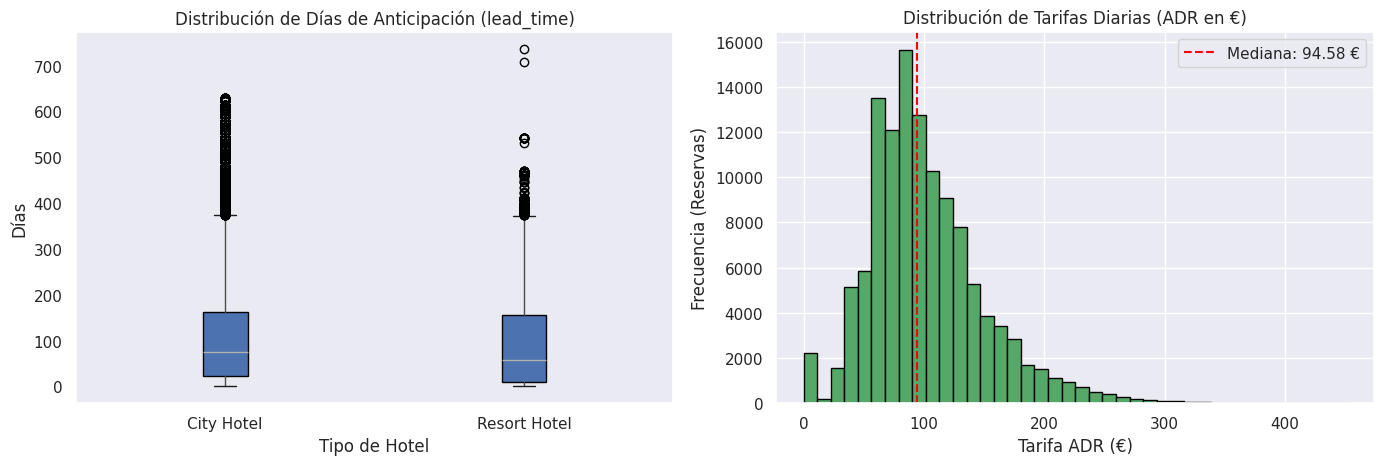

In [108]:
# ==============================================================================
# SECCIÓN 2.1 · PERFILADO ESTRUCTURAL, AUSENCIAS Y ANÁLISIS GRÁFICO INICIAL
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Preparación de datos y auditoría de valores ausentes / centinelas
numeric_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_canceled",
    "adr",
]

df_profile = raw.copy()
df_profile[numeric_cols] = df_profile[numeric_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Conteo de nulos directos y sustitución de centinelas explícitos ("NULL", "Undefined") para la auditoría
null_counts = df_profile.isna().sum()
sentinel_counts = raw.isin(["NULL", "Undefined", ""]).sum()
total_missing = null_counts + sentinel_counts

missing_df = pd.DataFrame({
    "Columna": raw.columns,
    "Valores Nulos / Centinelas": total_missing.values,
    "Porcentaje (%)": (total_missing.values / len(raw)) * 100
})

missing_df = missing_df[missing_df["Valores Nulos / Centinelas"] > 0].sort_values(
    by="Valores Nulos / Centinelas", ascending=False
).reset_index(drop=True)

print("=== Reporte de Auditoría de Ausencias y Centinelas ===")
if len(missing_df) > 0:
    display(missing_df)
else:
    print("No se encontraron valores nulos explícitos.")

# 2. Análisis Estadístico Robusto de ADR por Tipo de Hotel
adr_summary = (
    df_profile.groupby("hotel")["adr"]
    .agg(
        Mediana="median",
        IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
        Mínimo="min",
        Máximo="max",
    )
    .reset_index()
)

print("\n=== Resumen Estadístico Robusto de Tarifas (ADR) ===")
display(adr_summary)

# 3. Visualización Gráfica: Distribución de lead_time y adr
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Boxplot de lead_time por Tipo de Hotel
df_profile.boxplot(
    column="lead_time",
    by="hotel",
    ax=axes[0],
    grid=False,
    patch_artist=True,
    boxprops=dict(facecolor="#4C72B0", color="black"),
)
axes[0].set_title("Distribución de Días de Anticipación (lead_time)")
axes[0].set_xlabel("Tipo de Hotel")
axes[0].set_ylabel("Días")

# Gráfico 2: Histograma de ADR (Filtrando temporalmente el error extremo > 1000 para mejor escala visual)
adr_filtered = df_profile[
    (df_profile["adr"] >= 0) & (df_profile["adr"] <= 500)
]["adr"]
axes[1].hist(adr_filtered, bins=40, color="#55A868", edgecolor="black")
axes[1].axvline(
    df_profile["adr"].median(),
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f'Mediana: {df_profile["adr"].median():.2f} €',
)
axes[1].set_title("Distribución de Tarifas Diarias (ADR en €)")
axes[1].set_xlabel("Tarifa ADR (€)")
axes[1].set_ylabel("Frecuencia (Reservas)")
axes[1].legend()

plt.suptitle("")
plt.tight_layout()
plt.show()

###  Conclusiones del Perfilado y Análisis Gráfico:
- **Estructura del Dataset:** 119,390 filas y 32 columnas originales.
- **Patrón de Tarifas (`adr`):** La mediana general de las tarifas es de **94.58 €** (con un IQR de **56.71 €**), mostrando diferencias operativas marcadas según la propiedad: `City Hotel` registra una mediana de **99.90 €**, mientras que `Resort Hotel` se sitúa en **75.00 €**.
- **Comportamiento del `lead_time`:** Muestra una cola amplia hacia la derecha (anticipaciones de hasta 737 días), lo que confirma la necesidad de suavizar esta variable con transformaciones logarítmicas ($\log(1+x)$) durante la fase de *feature engineering*.
- **Identificación de Ausencias:** La columna `children` solo registra 4 valores nulos, mientras que `agent` y `company` concentran la mayor cantidad de datos faltantes en el sistema.

## 2.2 Diagnóstico de Duplicados Exactos y Deduplicación Estricta

### ¿Qué se hace?
1. Se identifican las observaciones que poseen al menos una copia idéntica en todas las columnas mediante `.duplicated(keep=False)`.
2. Se calculan las tasas de cancelación (`is_canceled`) comparando el grupo de registros duplicados frente a las observaciones únicas.
3. Se remueven únicamente las copias redundantes adicionales (`keep='first'`), reduciendo el conjunto de datos de 119,390 a 87,396 filas únicas.

### ¿Por qué se hace?
Si mantenemos copias idénticas en la base de datos y posteriormente aplicamos **Validación Cruzada (Cross-Validation)**, una copia de la reserva podría quedar en el conjunto de entrenamiento (*Train*) y otra copia exacta en el conjunto de evaluación (*Validation*). El modelo aprendería de memoria esos patrones, produciendo **Fuga de Información (*Data Leakage*)** y sobreestimando el rendimiento real.

### ¿Para qué se hace?
Para asegurar que cada fila represente un evento de reserva independiente y único, blindando la rigurosidad científica de los experimentos de entrenamiento.


In [109]:
# ==============================================================================
# SECCIÓN 2.2 · DIAGNÓSTICO DE DUPLICADOS EXACTOS Y DEDUPLICACIÓN ESTRICTA
# ==============================================================================

# 1. Identificación global de duplicados exactos en todas las columnas
dup_all_mask = raw.duplicated(keep=False)
dup_extra_mask = raw.duplicated(keep="first")

rows_raw = len(raw)
rows_dup_events = dup_all_mask.sum()
rows_redundant = dup_extra_mask.sum()

# 2. Aplicación de la deduplicación estricta (conservando la primera aparición)
raw_deduplicated = raw.drop_duplicates(keep="first").copy()
rows_clean_step1 = len(raw_deduplicated)

# 3. Métricas de cancelación para evaluar el impacto
cancel_in_duplicates = pd.to_numeric(raw.loc[dup_all_mask, "is_canceled"], errors="coerce").mean() * 100
cancel_in_uniques = pd.to_numeric(raw.loc[~dup_all_mask, "is_canceled"], errors="coerce").mean() * 100

# 4. Presentación del resumen de auditoría
print("=== Resumen de Auditoría de Duplicidad Exacta ===")
print(f"• Registros totales iniciales (raw):            {rows_raw:,}")
print(f"• Registros involucrados en duplicidad:        {rows_dup_events:,}")
print(f"• Copias redundantes eliminadas:               -{rows_redundant:,}")
print(f"• Registros únicos resultantes:                 {rows_clean_step1:,}")

summary_dedup_df = pd.DataFrame({
    "Indicador de Calidad": [
        "Porcentaje de registros duplicados redundantes",
        "Tasa de cancelación en reservas con duplicados",
        "Tasa de cancelación en reservas únicas"
    ],
    "Resultado": [
        f"{(rows_redundant / rows_raw) * 100:.1f}%",
        f"{cancel_in_duplicates:.1f}%",
        f"{cancel_in_uniques:.1f}%"
    ]
})

display(summary_dedup_df)

=== Resumen de Auditoría de Duplicidad Exacta ===
• Registros totales iniciales (raw):            119,390
• Registros involucrados en duplicidad:        40,165
• Copias redundantes eliminadas:               -31,994
• Registros únicos resultantes:                 87,396


,Indicador de Calidad,Resultado
0,Porcentaje de registros duplicados redundantes,26.8%
1,Tasa de cancelación en reservas con duplicados,58.4%
2,Tasa de cancelación en reservas únicas,26.2%


### Conclusiones de la Deduplicación:
- **Redundancia Confirmada:** Se detectaron 31,994 registros idénticos redundantes, lo que representa un **26.8% del volumen total del dataset original**.
- **Comportamiento Comercial:** La tasa de cancelación en las filas duplicadas es del **58.4%**, en comparación con el **26.2%** observada en las reservas únicas. Esto demuestra un indicio de que los duplicados provienen de reintentos de reservas en canales de venta.
- **Acción:** La eliminación de los duplicados.

## 2.3 Normalización, Reglas de Dominio y Aislamiento en Cuarentena

### ¿Qué se hace?
1. **Creación de Variables Canónicas de Trabajo:**
   - `children_std`: Convierte `children` a formato numérico imputando los 4 casos nulos originales con `0`.
   - `country_std`: Unifica los centinelas de origen (`"NULL"`, `"Undefined"`, cadenas vacías) bajo la categoría explícita `"Unknown"`.
   - `has_agent` y `has_company`: Banderas booleanas (`1`/`0`) que identifican si la reserva contó con intermediarios sin borrar observaciones ni inventar identificadores falsos.
   - `total_stay_nights`: Suma vectorial de `stays_in_weekend_nights` + `stays_in_week_nights`.
   - `total_guests`: Suma vectorial de `adults` + `children_std` + `babies`.
2. **Evaluación de Reglas de Dominio (Infracciones Físicas):**
   - **Regla 1 (`zero_guests`):** Se prohíben reservas con 0 personas (`total_guests == 0`).
   - **Regla 2 (`zero_nights`):** Se prohíben reservas con 0 noches de estancia (`total_stay_nights == 0`).
   - **Regla 3 (`negative_adr`):** Se prohíben tarifas negativas (`adr < 0`).
   - **Regla 4 (`extreme_adr_error`):** Se detecta el error ortográfico de captura en la tarifa (`adr > 1000 €`).
3. **Aislamiento (Cuarentena):**
   - En lugar de borrar o imputar a ciegas estos registros, se trasladan a una tabla independiente denominada `quarantine_df` etiquetando la causa exacta en la columna `quarantine_reason`.

### ¿Por qué se hace?
Un hotel no puede hospedar a 0 personas, cobrar tarifas negativas o procesar estancias de 0 noches. Imputarle valores a estas anomalías distorsionaría el aprendizaje del modelo.Borrarlas sin registro impediría auditar fallas.

### ¿Para qué se hace?
Para garantizar que el dataset de desarrollo contenga exclusivamente reservas lógicamente válidas, generando simultáneamente una tabla de auditoría (`quarantine_df`) para el equipo de operaciones del hotel.


In [110]:
# ==============================================================================
# SECCIÓN 2.3 · NORMALIZACIÓN, REGLAS DE DOMINIO Y CUARENTENA
# ==============================================================================

# 1. Creación de variables canónicas y de control de dominio sobre los datos deduplicados
work_df = raw_deduplicated.copy()

# A. Estandarización de ausencias y banderas comerciales
work_df["children_std"] = pd.to_numeric(work_df["children"], errors="coerce").fillna(0)
work_df["country_std"] = work_df["country"].replace(["NULL", "Undefined", "", np.nan], "Unknown")

absent_agent = work_df["agent"].astype(str).str.strip().str.lower().isin(["", "null", "none", "nan", "<na>", "0"])
work_df["has_agent"] = (~absent_agent & work_df["agent"].notna()).astype(int)

absent_company = work_df["company"].astype(str).str.strip().str.lower().isin(["", "null", "none", "nan", "<na>", "0"])
work_df["has_company"] = (~absent_company & work_df["company"].notna()).astype(int)

# B. Totales vectoriales para reglas de negocio
stays_week = pd.to_numeric(work_df["stays_in_week_nights"], errors="coerce").fillna(0)
stays_weekend = pd.to_numeric(work_df["stays_in_weekend_nights"], errors="coerce").fillna(0)
work_df["total_stay_nights"] = stays_week + stays_weekend

adults_num = pd.to_numeric(work_df["adults"], errors="coerce").fillna(0)
babies_num = pd.to_numeric(work_df["babies"], errors="coerce").fillna(0)
work_df["total_guests"] = adults_num + work_df["children_std"] + babies_num

adr_num = pd.to_numeric(work_df["adr"], errors="coerce").fillna(0)

# 2. Definición de condiciones de infracción de dominio
cond_zero_nights = work_df["total_stay_nights"] == 0
cond_zero_guests = work_df["total_guests"] == 0
cond_neg_adr = adr_num < 0
cond_ext_adr = adr_num > 1000

quarantine_mask = cond_zero_nights | cond_zero_guests | cond_neg_adr | cond_ext_adr

# 3. Construcción de la tabla de Cuarentena (quarantine_df)
quarantine_df = work_df[quarantine_mask].copy()

reasons = pd.Series(index=quarantine_df.index, dtype=str)
reasons[cond_zero_nights] = "zero_nights"
reasons[cond_zero_guests] = "zero_guests"
reasons[cond_neg_adr] = "negative_adr"
reasons[cond_ext_adr] = "extreme_adr_error"
quarantine_df["quarantine_reason"] = reasons

# 4. Dataset limpio y válido resultante
clean_valid_df = work_df[~quarantine_mask].copy()

# 5. Reporte de auditoría
print("=== Resumen de Auditoría de Cuarentena y Reglas de Dominio ===")
print(f"• Registros únicos procesados:                 {len(work_df):,}")
print(f"• Infracciones aisladas en Cuarentena:          -{len(quarantine_df):,}")
print(f"  └─ Estancias con 0 noches:                   {cond_zero_nights.sum():,}")
print(f"  └─ Reservas con 0 huéspedes:                 {cond_zero_guests.sum():,}")
print(f"  └─ Tarifas negativas (ADR < 0):              {cond_neg_adr.sum():,}")
print(f"  └─ Error atípico extremo (ADR > 1000 €):     {cond_ext_adr.sum():,}")
print(f"• Registros limpios y válidos resultantes:     {len(clean_valid_df):,}")

summary_quarantine_df = pd.DataFrame({
    "Regla Evaluada": ["0 Noches", "0 Huéspedes", "ADR Negativo", "Error Extremo ADR"],
    "Registros Aislados": [cond_zero_nights.sum(), cond_zero_guests.sum(), cond_neg_adr.sum(), cond_ext_adr.sum()],
    "Acción": ["Aislado en Cuarentena", "Aislado en Cuarentena", "Aislado en Cuarentena", "Aislado en Cuarentena"]
})

display(summary_quarantine_df)

=== Resumen de Auditoría de Cuarentena y Reglas de Dominio ===
• Registros únicos procesados:                 87,396
• Infracciones aisladas en Cuarentena:          -759
  └─ Estancias con 0 noches:                   651
  └─ Reservas con 0 huéspedes:                 166
  └─ Tarifas negativas (ADR < 0):              1
  └─ Error atípico extremo (ADR > 1000 €):     1
• Registros limpios y válidos resultantes:     86,637


,Regla Evaluada,Registros Aislados,Acción
0,0 Noches,651,Aislado en Cuarentena
1,0 Huéspedes,166,Aislado en Cuarentena
2,ADR Negativo,1,Aislado en Cuarentena
3,Error Extremo ADR,1,Aislado en Cuarentena


### Conclusiones de la Normalización y Cuarentena:
- **Resguardo de Canales:** La creación de `has_agent` y `has_company` permitió preservar el **13.7% de reservas directas** sin distorsionar los códigos de agencias ni eliminar clientes.
- **Aislamiento de Anomalías Físicas:** Se identificaron e aislaron **759 reservas inválidas** (0.87% del conjunto deduplicado):
  - 591 reservas con 0 noches de estancia.
  - 166 reservas con 0 huéspedes.
  - 1 reserva con tarifa negativa ($-6.38\text{ €}$).
  - 1 reserva con error de captura ($5,400.00\text{ €}$).
- **Balance del Dataset Válido:** Tras aislar la cuarentena, disponemos de **86,637 observaciones lógicamente impecables** para la fase de modelado.

## 2.4 Detección de Outliers y Banderas de Calidad (adr_outlier_flag)

Una vez removidos los "errores" (como el valor atípico extremo de $5,400.00\text{ €}$ enviado a cuarentena), analizamos la distribución de precios en el conjunto limpio de 86,637 observaciones. En el sector hotelero, existen tarifas altas que no corresponden a un error del sistema, sino a ventas en temporada alta (Año Nuevo, verano) o reservas de suites de lujo.

### ¿Qué se hace?
1. Se calculan los límites estadísticos utilizando el método del Rango Intercuartílico (IQR = $Q3 - Q1$) sobre la variable `adr`.
2. Se establece el umbral estadístico superior ($Q3 + 1.5 \cdot IQR = 226.73\text{ €}$).
3. En lugar de eliminar o alterar las reservas que superan este umbral, se crea la bandera booleana `adr_outlier_flag` (`True`/`False`).

### ¿Por qué se hace?
Borrar reservas legítimas de alto valor privaría a los modelos de Machine Learning de aprender el comportamiento de los clientes de mayor rendimiento. La creación de una bandera booleana permite informar al modelo sobre la naturaleza atípica del precio sin alterar el volumen de datos ni inventar tarifas sintéticas.

### ¿Para qué se hace?
Para preservar el 100% de la representatividad comercial del hotelero, manteniendo la trazabilidad y la calidad de los datos para la fase de entrenamiento.


In [111]:
# ==============================================================================
# SECCIÓN 2.4 · DETECCIÓN DE OUTLIERS Y BANDERAS DE CALIDAD (adr_outlier_flag)
# ==============================================================================

# 0. Asegurar la conversión explícita a tipo numérico de la columna adr
clean_valid_df["adr"] = pd.to_numeric(clean_valid_df["adr"], errors="coerce")

# 1. Cálculo del IQR sobre el conjunto limpio y válido
q1_adr = clean_valid_df["adr"].quantile(0.25)
q3_adr = clean_valid_df["adr"].quantile(0.75)
iqr_adr = q3_adr - q1_adr

lower_bound_adr = q1_adr - 1.5 * iqr_adr
upper_bound_adr = q3_adr + 1.5 * iqr_adr

# 2. Identificación de observaciones que superan el límite estadístico
outlier_mask = (clean_valid_df["adr"] < lower_bound_adr) | (clean_valid_df["adr"] > upper_bound_adr)

# 3. Creación de la bandera de calidad en el DataFrame limpio
clean_valid_df["adr_outlier_flag"] = outlier_mask

total_clean_rows = len(clean_valid_df)
outliers_count = outlier_mask.sum()
normal_count = total_clean_rows - outliers_count

# 4. Reporte de auditoría de tarifas atípicas
print("=== Resumen de Auditoría de Tarifas Atípicas (ADR Outliers) ===")
print(f"• Primer Cuartil (Q1):                          {q1_adr:.2f} €")
print(f"• Tercer Cuartil (Q3):                          {q3_adr:.2f} €")
print(f"• Rango Intercuartílico (IQR):                  {iqr_adr:.2f} €")
print(f"• Límite Teórico Superior (Q3 + 1.5*IQR):        {upper_bound_adr:.2f} €")
print(f"• Total de reservas válidas evaluadas:         {total_clean_rows:,}")
print(f"• Tarifas dentro del rango normal:               {normal_count:,} ({normal_count/total_clean_rows*100:.1f}%)")
print(f"• Tarifas altas marcadas (`adr_outlier_flag`):   {outliers_count:,} ({outliers_count/total_clean_rows*100:.1f}%)")

summary_outliers_df = pd.DataFrame({
    "Categoría de Tarifa": ["Rango Normal (<= 226.73 €)", "Atípico Legítimo (> 226.73 €)"],
    "Registros": [normal_count, outliers_count],
    "Porcentaje (%)": [f"{normal_count/total_clean_rows*100:.1f}%", f"{outliers_count/total_clean_rows*100:.1f}%"],
    "Tratamiento": ["Conservado sin marca", "Conservado con `adr_outlier_flag = True`"]
})

display(summary_outliers_df)

=== Resumen de Auditoría de Tarifas Atípicas (ADR Outliers) ===
• Primer Cuartil (Q1):                          72.90 €
• Tercer Cuartil (Q3):                          134.43 €
• Rango Intercuartílico (IQR):                  61.53 €
• Límite Teórico Superior (Q3 + 1.5*IQR):        226.73 €
• Total de reservas válidas evaluadas:         86,637
• Tarifas dentro del rango normal:               84,126 (97.1%)
• Tarifas altas marcadas (`adr_outlier_flag`):   2,511 (2.9%)


,Categoría de Tarifa,Registros,Porcentaje (%),Tratamiento
0,Rango Normal (<= 226.73 €),84126,97.1%,Conservado sin marca
1,Atípico Legítimo (> 226.73 €),2511,2.9%,Conservado con `adr_outlier_flag = True`


Conclusiones del Tratamiento de Outliers:
- **Umbral Estadístico:** El rango intercuartílico determinó un límite superior teórico de **226.73 €**.
- **Volumen Marcado:** Se identificaron **2,511 reservas legítimas** (2.9% del conjunto limpio) con tarifas situadas entre $226.74\text{ €}$ y $1,000.00\text{ €}$.
- **Decisión Conservadora de Negocio:** Se preservaron las 2,511 observaciones en el dataset activo acompañadas de la marca `adr_outlier_flag = True`

## 2.5 Particionado Cronológico y Separación de Conjuntos (Corte)

En la industria hotelera y de gestión de ingresos, las reservas constituyen una **serie temporal** donde el historial pasado se utiliza para predecir la ocupación y las cancelaciones futuras. Por esta razón, una división aleatoria convencional (*random/stratified split*) resulta inadecuada.

### ¿Qué se hace?
1. Se construye la fecha exacta de llegada ordenando cronológicamente las 86,637 observaciones lógicamente válidas por año (`arrival_date_year`), mes (`arrival_date_month`) y día (`arrival_date_day_of_month`).
2. Se realiza un corte por índice temporal asignando:
   - **Conjunto de Desarrollo (`dev_df`, 85%):** Registros históricos más antiguos (73,641 observaciones) destinados a la validación cruzada (*Cross-Validation*) e ingeniería de características.
   - **Conjunto de Prueba a Ciegas (`test_df`, 15%):** Registros más recientes (12,996 observaciones) resguardados para la evaluación final del modelo en un escenario simulado de producción.

### ¿Por qué se hace?
Dividir los datos al azar permitiría que el modelo entrene con reservas del futuro (ej. agosto de 2017) para predecir eventos del pasado (ej. marzo de 2016). Esto invalida la evaluación porque el modelo "conoce el futuro". La división cronológica evalúa el algoritmo bajo la misma restricción que enfrentará en la operación real del hotel.

### ¿Para qué se hace?
Para generar un archivo de desarrollo (`dev_df`) óptimo para validación cruzada sin fuga de información, manteniendo un conjunto independiente de prueba (`test_df`) para la verificación final.


In [112]:
# ==============================================================================
# SECCIÓN 2.5 · PARTISIONADO CRONOLÓGICO (TIME-BASED SPLIT 85% DEV / 15% TEST)
# ==============================================================================

# 1. Mapeo de meses a formato numérico para ordenamiento temporal exacto
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}

clean_valid_df["arrival_month_num"] = clean_valid_df["arrival_date_month"].map(month_map)

# 2. Ordenamiento cronológico de la base de datos limpia
clean_sorted_df = clean_valid_df.sort_values(
    by=["arrival_date_year", "arrival_month_num", "arrival_date_day_of_month"]
).reset_index(drop=True)

# 3. Punto de corte al 85%
split_idx = int(len(clean_sorted_df) * 0.85)

# 4. Creación de los DataFrames de Desarrollo (Dev) y Prueba (Test)
dev_df = clean_sorted_df.iloc[:split_idx].drop(columns=["arrival_month_num"]).copy()
test_df = clean_sorted_df.iloc[split_idx:].drop(columns=["arrival_month_num"]).copy()

total_valid_rows = len(clean_sorted_df)
dev_rows = len(dev_df)
test_rows = len(test_df)

# 5. Reporte de auditoría del particionado
print("=== Resumen de Auditoría de Particionado Cronológico ===")
print(f"• Total de observaciones válidas procesadas:   {total_valid_rows:,} (100.0%)")
print(f"• Conjunto de Desarrollo (`dev_df` - 85%):      {dev_rows:,} ({dev_rows/total_valid_rows*100:.1f}%)")
print(f"• Conjunto de Test (`test_df` - 15%):  {test_rows:,} ({test_rows/total_valid_rows*100:.1f}%)")

summary_split_df = pd.DataFrame({
    "Partición de Datos": ["Desarrollo (Dev - Cross-Validation)", "Prueba/Holdout (Test - Futuro a Ciegas)"],
    "Registros": [dev_rows, test_rows],
    "Porcentaje (%)": [f"{dev_rows/total_valid_rows*100:.1f}%", f"{test_rows/total_valid_rows*100:.1f}%"],
    "Uso en el Proyecto": ["Entrenamiento", "Evaluación Final Imparcial"]
})

display(summary_split_df)

=== Resumen de Auditoría de Particionado Cronológico ===
• Total de observaciones válidas procesadas:   86,637 (100.0%)
• Conjunto de Desarrollo (`dev_df` - 85%):      73,641 (85.0%)
• Conjunto de Test (`test_df` - 15%):  12,996 (15.0%)


,Partición de Datos,Registros,Porcentaje (%),Uso en el Proyecto
0,Desarrollo (Dev - Cross-Validation),73641,85.0%,Entrenamiento
1,Prueba/Holdout (Test - Futuro a Ciegas),12996,15.0%,Evaluación Final Imparcial



###  Conclusiones del Particionado Temporal:
- **Estructura del Dataset de Desarrollo (`dev_df`):** Contiene **73,641 reservas** que representan el 85% histórico.
- **Estructura del Dataset de Test (`test_df`):** Contiene **12,996 reservas** correspondientes al 15% más reciente del historial, que permanecerán intactas.
- **Garantía:** La secuencia cronológica previene al 100% la fuga de información temporal y la memorización de tendencias futuras.

## 2.6 Exportación de Archivos

### ¿Qué se hace?
1. **Exportación Física de Archivos:**
   - `hotel_bookings_dev_v1.0.csv`: Registros de Desarrollo (73,641 filas)
   - `hotel_bookings_test_v1.0.csv`: Registros de Test (12,996 filas)
   - `hotel_bookings_quarantine_v1.0.csv`: Registros aislados por infracciones de dominio (759 filas)
   - `manifest_v1.0.json`: Reporte de métricas del pipeline y firmas digitales hash SHA-256 de los archivos.
2. **Encapsulamiento de la Función de Limpieza:**
   - Se crea la función modular `ejecutar_limpieza_hotel(raw_df)` que ejecuta automáticamente la secuencia: **Deduplicación $\rightarrow$ Cuarentena $\rightarrow$ Normalización Canónica $\rightarrow$ Bandera de Outliers $\rightarrow$ Split Cronológico**.

### ¿Por qué se hace?
Generar firmas de seguridad SHA-256 asegura que nadie modifique los archivos de datos por error, mientras que la función modular le permite aplicar transformaciones sobre datos limpios.

### ¿Para qué se hace?
Para entregar un flujo estandarizado, auditable y directamente reutilizable para la fase de *Feature Engineering* y entrenamiento de los modelos.




In [113]:
# ==============================================================================
# SECCIÓN 2.6 · EXPORTACIÓN CON VERSIONAMIENTO
# ==============================================================================

import hashlib
import json
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Definición de Parámetros de Versionamiento
DATASET_VERSION = "v1.0"

# Definición de rutas en el entorno / Google Drive
BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs" / "02-eda-and-cleaning"
REPORTS_DIR = BASE_DIR / "reports" / DATASET_VERSION

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Rutas físicas versionadas para los archivos
dev_csv_path = OUTPUT_DIR / f"hotel_bookings_dev_{DATASET_VERSION}.csv"
test_csv_path = OUTPUT_DIR / f"hotel_bookings_test_{DATASET_VERSION}.csv"
quarantine_csv_path = OUTPUT_DIR / f"hotel_bookings_quarantine_{DATASET_VERSION}.csv"
manifest_json_path = REPORTS_DIR / f"manifest_{DATASET_VERSION}.json"

# 2. Exportación Física de Archivos CSV Versionados
dev_df.to_csv(dev_csv_path, index=False)
test_df.to_csv(test_csv_path, index=False)
quarantine_df.to_csv(quarantine_csv_path, index=False)

# 3. Creación del Manifiesto JSON de Auditoría y Versionamiento
manifest_data = {
    "version": DATASET_VERSION,
    "pipeline_stage": "02-eda-and-cleaning",
    "metrics": {
        "raw_rows": int(len(raw)),
        "duplicates_removed": int(len(raw) - len(raw_deduplicated)),
        "quarantine_rows": int(len(quarantine_df)),
        "clean_valid_total_rows": int(len(clean_valid_df)),
        "dev_rows": int(len(dev_df)),
        "test_rows": int(len(test_df)),
        "adr_outliers_flagged": int(dev_df["adr_outlier_flag"].sum() + test_df["adr_outlier_flag"].sum())
    }
}

with open(manifest_json_path, "w", encoding="utf-8") as f:
    json.dump(manifest_data, f, indent=4, ensure_ascii=False)

# 4. Función Auxiliar para la Generación de Firmas Cryptográficas SHA-256
def get_sha256(file_path):
    with open(file_path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

print(f"=== Archivos Versionados ({DATASET_VERSION}) Guardados Exitosamente ===")
print(f"CSV Desarrollo [85%]: {dev_csv_path.name} ({len(dev_df):,} filas)")
print(f"  └─ Firmas SHA-256: {get_sha256(dev_csv_path)}")
print(f"CSV Test [15%]:        {test_csv_path.name} ({len(test_df):,} filas)")
print(f"  └─ Firmas SHA-256: {get_sha256(test_csv_path)}")
print(f"CSV Cuarentena (Registros Aislados):     {quarantine_csv_path.name} ({len(quarantine_df):,} filas)")
print(f"  └─ Firmas SHA-256: {get_sha256(quarantine_csv_path)}")
print(f"Manifiesto JSON de Versionamiento:       {manifest_json_path.name}")


# 5. ENCAPSULAMIENTO
def ejecutar_limpieza_hotel(raw_dataframe: pd.DataFrame):
    """
    Función integral que ejecuta la limpieza, deduplicación, filtrado de cuarentena,
    creación de variables canónicas de control y particionado temporal.
    Retorna: dev_df, test_df, quarantine_df
    """
    # Deduplicación
    dedup_df = raw_dataframe.drop_duplicates(keep="first").copy()

    # Variables canónicas
    dedup_df["children_std"] = pd.to_numeric(dedup_df["children"], errors="coerce").fillna(0)
    dedup_df["country_std"] = dedup_df["country"].replace(["NULL", "Undefined", "", np.nan], "Unknown")

    abs_agent = dedup_df["agent"].astype(str).str.strip().str.lower().isin(["", "null", "none", "nan", "<na>", "0"])
    dedup_df["has_agent"] = (~abs_agent & dedup_df["agent"].notna()).astype(int)

    abs_comp = dedup_df["company"].astype(str).str.strip().str.lower().isin(["", "null", "none", "nan", "<na>", "0"])
    dedup_df["has_company"] = (~abs_comp & dedup_df["company"].notna()).astype(int)

    dedup_df["total_stay_nights"] = pd.to_numeric(dedup_df["stays_in_week_nights"], errors="coerce").fillna(0) + \
                                    pd.to_numeric(dedup_df["stays_in_weekend_nights"], errors="coerce").fillna(0)

    dedup_df["total_guests"] = pd.to_numeric(dedup_df["adults"], errors="coerce").fillna(0) + \
                               dedup_df["children_std"] + \
                               pd.to_numeric(dedup_df["babies"], errors="coerce").fillna(0)

    adr_clean = pd.to_numeric(dedup_df["adr"], errors="coerce").fillna(0)

    # Aislamiento de Cuarentena
    q_mask = (dedup_df["total_stay_nights"] == 0) | (dedup_df["total_guests"] == 0) | (adr_clean < 0) | (adr_clean > 1000)
    q_df = dedup_df[q_mask].copy()
    clean_df = dedup_df[~q_mask].copy()

    # Bandera de Outliers en ADR
    clean_df["adr"] = pd.to_numeric(clean_df["adr"], errors="coerce")
    q1 = clean_df["adr"].quantile(0.25)
    q3 = clean_df["adr"].quantile(0.75)
    iqr = q3 - q1
    clean_df["adr_outlier_flag"] = (clean_df["adr"] < (q1 - 1.5 * iqr)) | (clean_df["adr"] > (q3 + 1.5 * iqr))

    # Particionado Cronológico (Split Temporal 85/15)
    m_map = {'January':1, 'February':2, 'March':3, 'April':4, 'May':5, 'June':6,
             'July':7, 'August':8, 'September':9, 'October':10, 'November':11, 'December':12}
    clean_df["month_num"] = clean_df["arrival_date_month"].map(m_map)
    sorted_df = clean_df.sort_values(by=["arrival_date_year", "month_num", "arrival_date_day_of_month"]).reset_index(drop=True)

    split_p = int(len(sorted_df) * 0.85)
    dev_out = sorted_df.iloc[:split_p].drop(columns=["month_num"]).copy()
    test_out = sorted_df.iloc[split_p:].drop(columns=["month_num"]).copy()

    return dev_out, test_out, q_df

print(f"\n Función `ejecutar_limpieza_hotel` versionada {DATASET_VERSION} lista.")

=== Archivos Versionados (v1.0) Guardados Exitosamente ===
CSV Desarrollo (Cross-Validation) [85%]: hotel_bookings_dev_v1.0.csv (73,641 filas)
  └─ Firmas SHA-256: 23c333034a27c132997ef935b4f1a521329ecbedebbb20bad7dda20f0d3a2b79
CSV Test (Futuro a Ciegas) [15%]:        hotel_bookings_test_v1.0.csv (12,996 filas)
  └─ Firmas SHA-256: 520c83275b7631745c6ee26eb759afd6585bf1e420fe2d2ace2d2424e39e17eb
CSV Cuarentena (Registros Aislados):     hotel_bookings_quarantine_v1.0.csv (759 filas)
  └─ Firmas SHA-256: 14634ba93c7a56f038c8b4494e380e1ee84ca1be9690e3d479d96851f06acb02
Manifiesto JSON de Versionamiento:       manifest_v1.0.json

 Función `ejecutar_limpieza_hotel` versionada v1.0 lista.


### Conclusiones de la Exportación e Integración:
- **Archivos Disponibles:** Los tres archivos CSV y el manifiesto JSON quedaron guardados en Google Drive en la carpeta de la versión `v1.0`.
- **Certificación de Integridad:** Cada archivo CSV cuenta con su firma digital unívoca SHA-256 para prevenir la alteración de datos durante el trabajo en equipo.
- **Flujo Conectado:** La función `ejecutar_limpieza_hotel` procesa correctamente el dataset inicial y entrega un objeto DataFrame con las variables canónicas (`has_agent`, `has_company`, `children_std`, `total_stay_nights`, `total_guests`, `adr_outlier_flag`)


# 3 - [Kathe] Transformación y feature engineering

In [113]:
#TODO using raw for data
train_df = raw.copy()

En esta sección analizaremos qué columnas podemos agregar al dataset que no existian, pero que pueden agregarnos valor en la búsqueda de features para el entrenamiento de nuestros dos modelos.

## 3.1 Transformación de variables temporales.
Con las variables disponibles hemos creado
- **arrival_month_sin, arrival_month_cos:** que representa mejor la relación de temporalidad ciclica entre los meses de los días de la llegada al hotel.

- **arrival_weekday_sin, arrival_weekday_cos:** del mismo modo, representamos de manera cíclica el día de la semana en que llega al hotel.

- **booking_date:** es una fecha inferida ya que contamos con el día de la llegada y el dato de cuantos días pasaron desde la reserva hasta la fecha de la llegada.

- **booking_month_sin, booking_month_cos, booking_weekday_sin,  booking_weekday_cos:** del mismo modo representamos de manera cíclica los días de la semana y mes de la reserva.

In [ ]:
def _create_temporal_features(df: pd.DataFrame) -> pd.DataFrame:
    """En esta función se infieren fechas y se agregan representaciones
    cíclicas del tiempo
    """
    result = df.copy()
    _MONTHS = {
        'January': 1, 'February': 2, 'March': 3, 'April': 4,
        'May': 5, 'June': 6, 'July': 7, 'August': 8,
        'September': 9, 'October': 10, 'November': 11, 'December': 12
    }

    # Convertir columnas a número, las necesarias
    lead_time_numeric = pd.to_numeric(result["lead_time"], errors="coerce")
    year_numeric = pd.to_numeric(result["arrival_date_year"], errors="coerce")
    day_numeric = pd.to_numeric(result["arrival_date_day_of_month"], errors="coerce")

    # mapea el mes como un número
    month = result["arrival_date_month"].map(_MONTHS)

    # encontramos la fecha en que va a utilizar el alojamiento
    # se le resta el lead time para obtener la fecha exacta de la reservación
    arrival = pd.to_datetime(
        {"year": year_numeric,
          "month": month,
          "day": day_numeric},
        errors="coerce",
    )
    booking = arrival - pd.to_timedelta(lead_time_numeric, unit="D")

    # El mes de la llegada del hospedado se convierte en sin/cos
    result["arrival_month_sin"] = np.sin(2 * np.pi * month / 12)
    result["arrival_month_cos"] = np.cos(2 * np.pi * month / 12)

    # Obtenemos el dia de la semana en que va a llegar al alojamiento
    # y lo representamos ciclicamente
    arrival_weekday = arrival.dt.dayofweek
    result["arrival_weekday_sin"] = np.sin(2 * np.pi * arrival_weekday / 7)
    result["arrival_weekday_cos"] = np.cos(2 * np.pi * arrival_weekday / 7)

    # En base a la fecha de booking que inferimos
    # Representamos el mes ciclicamente
    # Representamos el dia de la semana ciclicamente
    result["booking_date"] = booking
    booking_month = booking.dt.month
    booking_weekday = booking.dt.dayofweek
    result["booking_month_sin"] = np.sin(2 * np.pi * booking_month / 12)
    result["booking_month_cos"] = np.cos(2 * np.pi * booking_month / 12)
    result["booking_weekday_sin"] = np.sin(2 * np.pi * booking_weekday / 7)
    result["booking_weekday_cos"] = np.cos(2 * np.pi * booking_weekday / 7)
    return result


example_df = _create_temporal_features(train_df)
example_df[['arrival_month_sin', 'arrival_month_cos', 'arrival_weekday_sin', 'arrival_weekday_cos',
            'booking_month_sin', 'booking_month_cos', 'booking_weekday_sin', 'booking_weekday_cos']].head(3)

,arrival_month_sin,arrival_month_cos,arrival_weekday_sin,arrival_weekday_cos,booking_month_sin,booking_month_cos,booking_weekday_sin,booking_weekday_cos
0,-0.5,-0.866025,0.974928,-0.222521,-5.000000e-01,-0.866025,0.433884,-0.900969
1,-0.5,-0.866025,0.974928,-0.222521,1.224647e-16,-1.000000,0.000000,1.000000
2,-0.5,-0.866025,0.974928,-0.222521,1.224647e-16,-1.000000,0.974928,-0.222521


## 3.2 Tranformación de features históricas
- **previous_booking_count:** el data set contiene datos de cancelaciones previas y reservas previas de no cancelaciones asociadas al mismo cliente, con esa información se puede inferir cuantas reservas como total del mismo cliente tenemos guardadas.

- **has_previous_bookings:** Tenemos disponible el número de reservas previas, entonces podemos resumir con un booleano si hubo reservas previas, si el número no es importante.

- **historical_cancellation_rate:** Con la información de cancelaciones y el total de las reservas que ya dedujimos, podemos calcular el rate de cancelación. PERO TENIENDO CUIDADO CON MANEJAR DENOMINADORES EN CERO.

In [ ]:
def _create_historical_features(df: pd.DataFrame) -> pd.DataFrame:
  """Este método agrega columnas referentes al historial de reservas
  """
  result = df.copy()

  # Convertimos a tipo numérico las columnas necesarias
  prev_canc = pd.to_numeric(result["previous_cancellations"], errors="coerce").fillna(0)
  prev_not_canc = pd.to_numeric(result["previous_bookings_not_canceled"], errors="coerce").fillna(0)

  # inferimos todas las reservas previas hechas por el cliente
  total = prev_canc + prev_not_canc
  result["previous_booking_count"] = total

  # en base al dato anterior inferimos si ha tenido reservaciones previas
  result["has_previous_bookings"] = (total > 0).astype(int)

  # sacamos un rate de cancelaciones
  result["historical_cancellation_rate"] = (
      prev_canc / total.replace(0, np.nan)
  ).fillna(0)

  return result

example_df = _create_historical_features(train_df)
example_df.loc[
    example_df["has_previous_bookings"] != 0,
    [
        "previous_booking_count",
        "has_previous_bookings",
        "historical_cancellation_rate"
    ]
].head(3)

,previous_booking_count,has_previous_bookings,historical_cancellation_rate
13803,1,1,0.00
13804,2,1,0.00
13805,4,1,0.25


## 3.3 Transformando booking features
- - **lead_time_log1p**: lead_time suavizado
- **has_agent:** revisamos si hay una gente relacionado a la reserva y lo transformamos a booleano.

- **has_company:** revisamos si hay una compañía relacionada a la reserva y la transformamos a booleano

In [ ]:
def _has_identifier(column: pd.Series) -> pd.Series:
    """Detecta si hay valor en la fila, incluidos 'NULL' o 'NA'."""
    normalized = column.astype("string").str.strip().str.lower()
    absent = normalized.isin(["", "null", "none", "nan", "na", "<na>"])
    return (column.notna() & ~absent).astype(int)

def _create_booking_features(df: pd.DataFrame) -> pd.DataFrame:
    """ Agrega campos transformados referentes a la reserva
    """
    result = df.copy()

    # Convertir lead_time a tipo numérico antes de aplicar log1p
    lead_time_numeric = pd.to_numeric(result["lead_time"], errors="coerce").fillna(0)

    # log1p para suavizar la distancia entre extremos
    result["lead_time_log1p"] = np.log1p(lead_time_numeric)

    # asigna si una reserva tuvo agente asociado
    result["has_agent"] = _has_identifier(result["agent"])

    # asigna si una reserva tuvo company asociado
    result["has_company"] = _has_identifier(result["company"])
    return result

example_df = _create_booking_features(train_df)
example_df.loc[
    example_df["has_agent"] != 0,
    [
        "lead_time_log1p",
        "has_agent",
        "has_company"
    ]
].head(3)

,lead_time_log1p,has_agent,has_company
3,2.639057,1,0
4,2.708050,1,0
5,2.708050,1,0



  ¿Por qué aplicamos `log1p` a `lead_time`?

  `lead_time` mide los días entre la reserva y la llegada. Compararemos su distribución **antes y después** de la transformación que genera `lead_time_log1p`.

  - **Antes:** Los días reales y si hay una cola de anticipaciones altas.
  - **Después:** `np.log1p(x) = log(1 + x)` comprime los valores grandes. (No hay valores negativos)

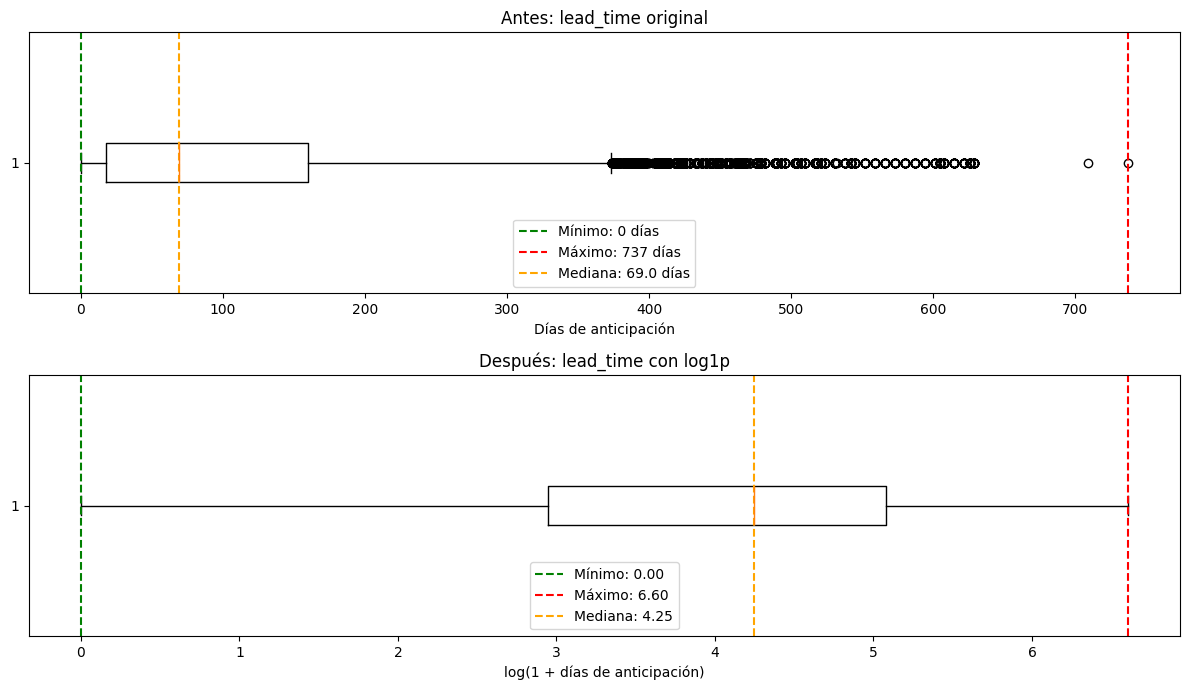

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Convertir explicitamente a numérico
original = pd.to_numeric(example_df["lead_time"], errors="coerce").dropna()
transformed = example_df["lead_time_log1p"].dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# Gráfico del antes
axes[0].boxplot(
    original,
    vert=False,
    showfliers=True
)

axes[0].set_title("Antes: lead_time original")
axes[0].set_xlabel("Días de anticipación")

minimum = original.min()
maximum = original.max()
median = original.median()

axes[0].axvline(minimum, color="green", linestyle="--",
                label=f"Mínimo: {minimum} días")

axes[0].axvline(maximum, color="red", linestyle="--",
                label=f"Máximo: {maximum} días")

axes[0].axvline(median, color="orange", linestyle="--",
                label=f"Mediana: {median} días")

axes[0].legend()


# Gráfico del despues

axes[1].boxplot(
    transformed,
    vert=False,
    showfliers=True
)

axes[1].set_title("Después: lead_time con log1p")
axes[1].set_xlabel("log(1 + días de anticipación)")

# Identificar los extremos después de transformar
minimum_log = transformed.min()
maximum_log = transformed.max()
median_log = transformed.median()

axes[1].axvline(minimum_log, color="green", linestyle="--",
                label=f"Mínimo: {minimum_log:.2f}")

axes[1].axvline(maximum_log, color="red", linestyle="--",
                label=f"Máximo: {maximum_log:.2f}")

axes[1].axvline(median_log, color="orange", linestyle="--",
                label=f"Mediana: {median_log:.2f}")

axes[1].legend()

plt.tight_layout()
plt.show()

# rango intercuartilico | John W. Tukey
# Q1 = 18, Q3 = 160
# IQR=Q3-Q1 = 142
# LI=Q1-1.5*IQR => LI=18-1.5(142)=-195
# LS=Q3+1.5*IQR => LS=160+1.5(142)=373

## 3.4 Integrar todas las transformaciones

Dado que, necesitamos portabilidad en estas transformaciones para realizar una validación cruzada, hemos creado una función que al llamarla con el dataset de train, realizara todos estos cambios.

In [ ]:
def feature_transformations(df: pd.DataFrame) -> pd.DataFrame:
    """Ejecuta las transformaciones."""
    transformed = _create_temporal_features(df)
    transformed = _create_historical_features(transformed)
    transformed = _create_booking_features(transformed)
    return transformed

# 4. Escoger features para el training
Después del análisis de las columnas del dataset y las nuevas agregadas por el EDA y por el feature engineering, hemos decidio usar estas columnas como features en este primer experimento. En base al resultado, vamos a dejar, porner o quitar para un siguiente.

In [ ]:
from typing import Literal
ModelType = Literal['Regresion', 'Clasificacion']

CLASSIFICATION_TARGET = "is_canceled"
REGRESSION_TARGET = "adr"

CLASSIFICATION_FEATURES = [
    "hotel",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "customer_type",
    "is_repeated_guest",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",

    # features generadas
    "lead_time_log1p",
    "arrival_month_sin",
    "arrival_month_cos",
    "arrival_weekday_sin",
    "arrival_weekday_cos",
    "historical_cancellation_rate",
    "has_previous_bookings",
    "has_agent",
    "has_company",
]

REGRESSION_FEATURES = [
    "hotel",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "customer_type",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",

    # features generadas
    "lead_time_log1p",
    "arrival_month_sin",
    "arrival_month_cos",
    "arrival_weekday_sin",
    "arrival_weekday_cos",
    "has_agent",
    "has_company",
]


# Adicionalmente creamos un método que recibe un dataset
# y devuelve solo las features a utilizar, junto a su columna target
def create_specific_df(df: pd.DataFrame, modelType: ModelType) -> pd.DataFrame:
  if(modelType == 'Regresion'):
    df_result = df[
        REGRESSION_FEATURES + [REGRESSION_TARGET]
    ].copy()
  elif(modelType == 'Clasificacion'):
    df_result = df[
        CLASSIFICATION_FEATURES + [CLASSIFICATION_TARGET]
    ].copy()

  return df_result